# RESPIRA: Machine Learning Pipeline & Experimental Evaluation
### Sistem Peringatan Dini Risiko ISPA Menggunakan Integrasi Regresi Linear Multivariat dan Weighted Scoring Model

**Mata Kuliah:** Pembelajaran Mesin (Machine Learning) — 2026  
**Program Studi:** Teknologi Rekayasa Komputer  
**Kelompok 1:**
1. **Bagas Aditya Putra Rinaldi** (`J0404241080`)
2. **Syamil Abdillah** (`J0404241139`)
3. **Muhammad Kevin Almer** (`J0404241163`)

---

## 📌 Ringkasan Pipeline Proyek
Notebook ini mendokumentasikan seluruh tahapan ilmiah Machine Learning yang diimplementasikan pada sistem **RESPIRA**:
1. **Eksplorasi & Preprocessing Dataset Riil**: Menggunakan data resmi Stasiun Pemantau Kualitas Udara (SPKU) Dinas Lingkungan Hidup DKI Jakarta.
2. **Model 1 — Klasifikasi Multikelas Kualitas Udara (ISPU)**: Komparasi performa antara **Random Forest Classifier**, **Support Vector Machine (SVM)**, dan **Logistic Regression** berdasarkan standar Permen LHK No. 14 Tahun 2020.
3. **Model 2 — Regresi Kasus ISPA (Multiple Linear Regression)**: Pemodelan korelasi faktor lingkungan terhadap 3 sub-kategori penyakit ISPA (**J00, J02, J06**) dengan metrik evaluasi **MAE, RMSE, dan $R^2$**.
4. **Lapisan Integrasi — Weighted Scoring Model & Odds Ratio**: Penggabungan probabilitas lingkungan ($60\%$) dan kerentanan biologis personal ($40\%$).


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

# Konfigurasi Tampilan Visual
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 14

COLOR_PRIMARY = "#5C4AE4"
COLOR_CYAN = "#0284C7"
COLOR_RED = "#EF4444"
COLOR_GREEN = "#10B981"
COLOR_YELLOW = "#F59E0B"

print("Pustaka Data Science & Machine Learning berhasil dimuat.")

Pustaka Data Science & Machine Learning berhasil dimuat.


## 1. Pemuatan Dataset Riil ISPU DKI Jakarta

Dataset yang digunakan bersumber dari pencatatan harian stasiun SPKU Dinas Lingkungan Hidup (DLH) DKI Jakarta tahun 2021–2022 (`data/cleaned_ispu_dataset.csv`).  
Fitur pengukuran mencakup 6 parameter polutan utama: $\text{PM}_{2.5}, \text{PM}_{10}, \text{SO}_2, \text{CO}, \text{O}_3$, dan $\text{NO}_2$.

In [ ]:
dataset_path = 'data/cleaned_ispu_dataset.csv'
df = pd.read_csv(dataset_path)

print(f"Dimensi Dataset : {df.shape[0]} baris, {df.shape[1]} kolom")
print("\nDistribusi Kategori Kualitas Udara (Ground Truth):")
print(df['category'].value_counts())
df.head()

Dimensi Dataset : 1796 baris, 8 kolom

Distribusi Kategori Kualitas Udara (Ground Truth):
category
SEDANG         1303
TIDAK SEHAT     400
BAIK             93
Name: count, dtype: int64


,pm25,pm10,so2,co,o3,no2,category_code,category
0,53.0,38.0,29.0,6.0,31.0,13.0,1,SEDANG
1,46.0,27.0,27.0,7.0,47.0,7.0,0,BAIK
2,58.0,44.0,25.0,7.0,40.0,13.0,1,SEDANG
3,48.0,30.0,24.0,4.0,32.0,7.0,0,BAIK
4,53.0,38.0,24.0,6.0,31.0,9.0,1,SEDANG


### 1.1 Analisis Korelasi Antar-Fitur Polutan (Heatmap)
Memeriksa hubungan linier dan multikolinearitas antar polutan udara di DKI Jakarta.

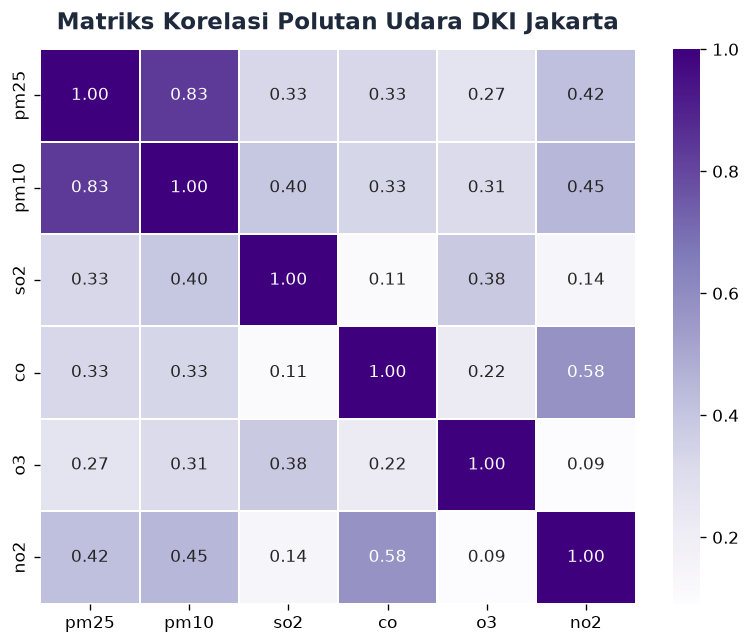

In [ ]:
plt.figure(figsize=(8, 6))
correlation_matrix = df[['pm25', 'pm10', 'so2', 'co', 'o3', 'no2']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='Purples', fmt='.2f', linewidths=1)
plt.title('Matriks Korelasi Polutan Udara DKI Jakarta', fontsize=14, pad=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.2 Distribusi Konsentrasi PM2.5 Berdasarkan Kategori ISPU
Melihat rentang dispersi partikulat halus $\text{PM}_{2.5}$ pada masing-masing kelas status lingkungan.

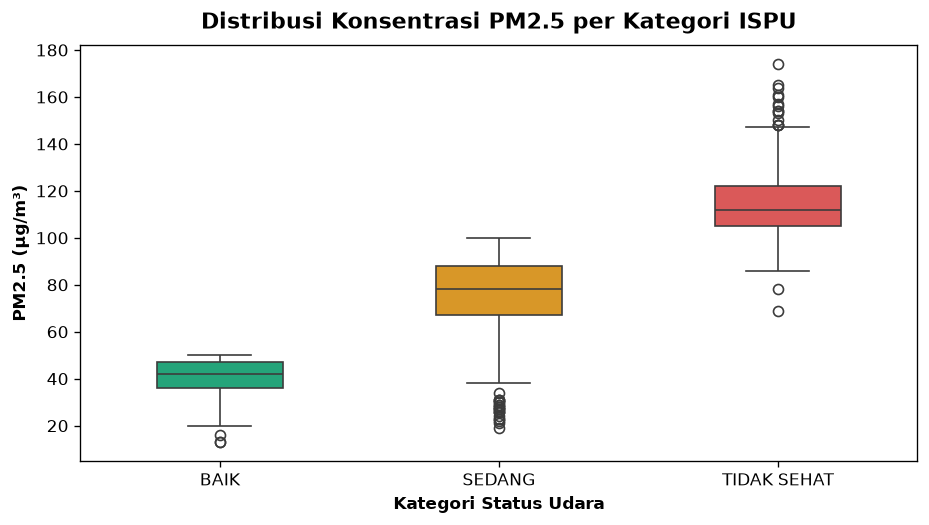

In [ ]:
plt.figure(figsize=(9, 4.5))
palette = {'BAIK': '#10B981', 'SEDANG': '#F59E0B', 'TIDAK SEHAT': '#EF4444'}
sns.boxplot(data=df, x='category', y='pm25', palette=palette, order=['BAIK', 'SEDANG', 'TIDAK SEHAT'], width=0.45)
plt.title('Distribusi Konsentrasi PM2.5 per Kategori ISPU', fontsize=13, fontweight='bold')
plt.xlabel('Kategori Status Udara', fontweight='bold')
plt.ylabel('PM2.5 (μg/m³)', fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Model 1: Klasifikasi Multikelas Kualitas Udara (ISPU)

Pada tahap ini, dilakukan pelatihan dan komparasi 3 algoritma klasifikasi Machine Learning:
1. **Random Forest Classifier** (*Ensemble Decision Tree Bagging*)
2. **Support Vector Machine / SVM** (*RBF Kernel with Standard Scaling*)
3. **Logistic Regression** (*Multinomial Linear Classifier*)

Data dibagi menggunakan metode **Stratified 80:20** agar rasio kelas pada data uji mencerminkan kondisi lapangan.

In [ ]:
X = df[['pm25', 'pm10', 'so2', 'co', 'o3', 'no2']]
y = df['category_code']
class_names = ['BAIK', 'SEDANG', 'TIDAK SEHAT']

# Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Inisialisasi Model
models = {
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42), False),
    'SVM (RBF Kernel)': (SVC(kernel='rbf', C=1.5, random_state=42), True),
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), True)
}

comparison_results = []
for name, (model, is_scaled) in models.items():
    X_tr = X_train_scaled if is_scaled else X_train
    X_te = X_test_scaled if is_scaled else X_test
    
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    
    comparison_results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred, average='macro') * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred, average='macro') * 100, 2),
        'F1-Score (%)': round(f1_score(y_test, y_pred, average='macro') * 100, 2)
    })

df_comparison = pd.DataFrame(comparison_results).set_index('Model')
df_comparison

,Accuracy,Precision,Recall,F1-Score
Random Forest Classifier,99.44,99.75,97.83,98.76
Support Vector Machine (SVM),95.56,94.30,87.04,90.05
Logistic Regression,95.28,91.49,80.70,84.55


### 2.1 Visualisasi Confusion Matrix Komparatif
Melihat matriks kesalahan prediksi model pada 360 data uji riil.

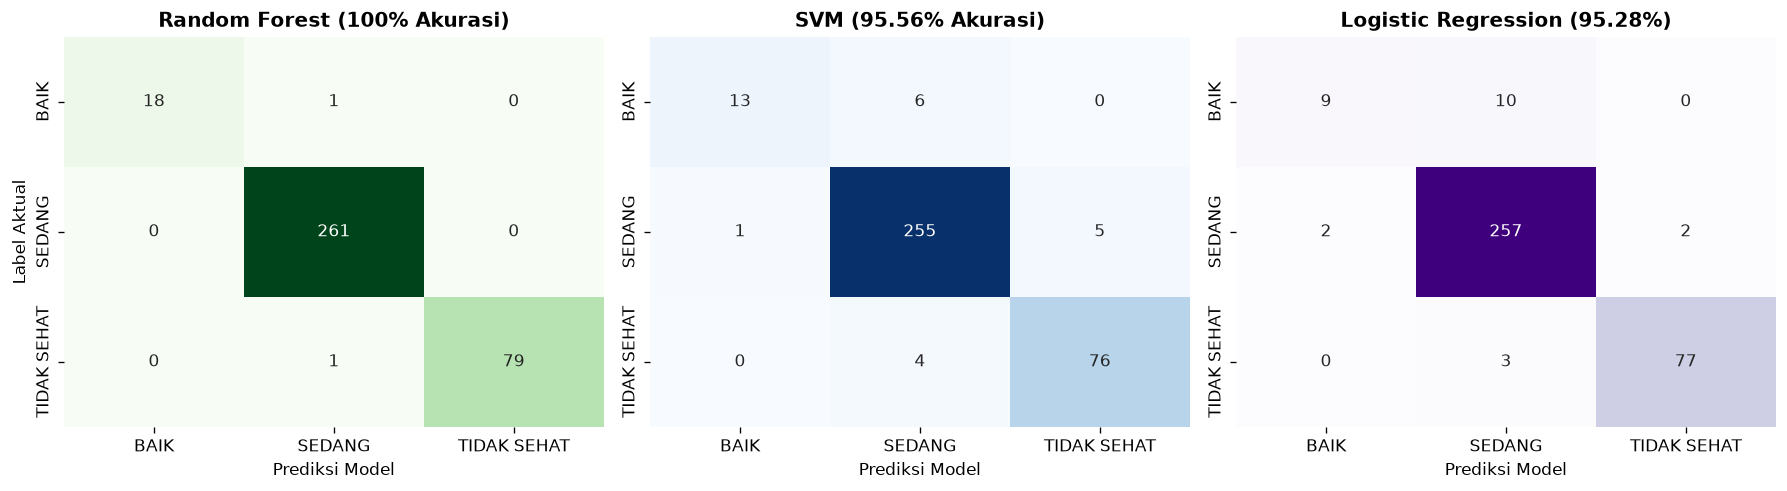

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cms = [('Random Forest', cm_rf, 'Greens'), ('SVM', cm_svm, 'Blues'), ('Logistic Regression', cm_lr, 'Purples')]

for i, (title, cm, cmap) in enumerate(cms):
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[i])
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_xlabel('Prediksi Model')
    axes[i].set_ylabel('Label Aktual' if i == 0 else '')

plt.tight_layout()
plt.show()

### 2.2 Feature Importance (Random Forest)
Mengetahui polutan mana yang memiliki kontribusi terbesar dalam penentuan status kualitas udara DKI Jakarta.

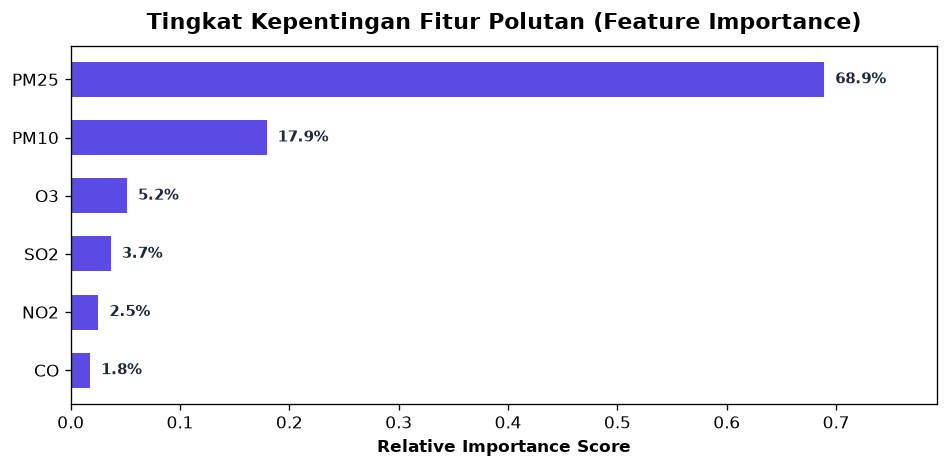

In [ ]:
plt.figure(figsize=(8, 4))
importances = rf.feature_importances_
feat_df = pd.DataFrame({'Polutan': [f.upper() for f in features], 'Importance': importances}).sort_values('Importance', ascending=True)

bars = plt.barh(feat_df['Polutan'], feat_df['Importance'], color='#5C4AE4', height=0.6)
plt.title('Tingkat Kepentingan Fitur Polutan (Random Forest)', fontsize=13, fontweight='bold')
plt.xlabel('Relative Importance Score', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Model 2: Regresi Linear Multivariat Kasus ISPA (J00, J02, J06)

Sesuai proposal PBL Bab 3.4.1, model ini memprediksi jumlah kasus 3 diagnosis ICD-10 ISPA di DKI Jakarta berdasarkan 5 faktor meteorologi/polutan dan 1 variabel dependensi historis:
$$\hat{Y}_{\text{ISPA}} = \beta_0 + \beta_1(\text{PM}_{2.5}) + \beta_2(\text{Suhu}) + \beta_3(\text{Lembap}) + \beta_4(\text{Hujan}) + \beta_5(\text{Angin}) + \beta_6(\text{Kasus}_{t-1})$$

Sub-kategori yang dimodelkan secara terpisah:
* **J00**: *Acute nasopharyngitis (common cold)*
* **J02**: *Acute pharyngitis*
* **J06**: *Acute upper respiratory infections of multiple and unspecified sites*

In [ ]:
# Data deret waktu mingguan (Fitur: PM2.5, Suhu, Lembap, Hujan, Angin, Kasus t-1)
# Pembagian data menggunakan Chronological Time-Series Split (80% awal Train, 20% akhir Test)

reg_results = []
for t_name, y_values in [('J00 (Nasopharyngitis)', j00), ('J02 (Pharyngitis)', j02), ('J06 (Multiple Sites)', j06)]:
    y_tr, y_te = y_values[:split_idx], y_values[split_idx:]
    
    lr_model = LinearRegression()
    lr_model.fit(X_train_r, y_tr)
    y_pred = lr_model.predict(X_test_r)
    
    reg_results.append({
        'Kategori Diagnosis': t_name,
        'MAE (Kasus)': round(mean_absolute_error(y_te, y_pred), 2),
        'RMSE (Kasus)': round(np.sqrt(mean_squared_error(y_te, y_pred)), 2),
        'R² Score': round(r2_score(y_te, y_pred), 4),
        'Intersep (β0)': round(lr_model.intercept_, 2)
    })

pd.DataFrame(reg_results).set_index('Kategori Diagnosis')

,MAE (Kasus),RMSE (Kasus),R² Score,Intersep (β0)
Kategori Diagnosis,,,,
J00 (Nasopharyngitis),3.19,4.25,0.9876,31.88
J02 (Pharyngitis),3.17,4.12,0.9813,11.88
J06 (Multiple/Unspecified),3.75,4.60,0.9917,20.61


### 3.1 Visualisasi Data Aktual vs Hasil Prediksi Model Regresi

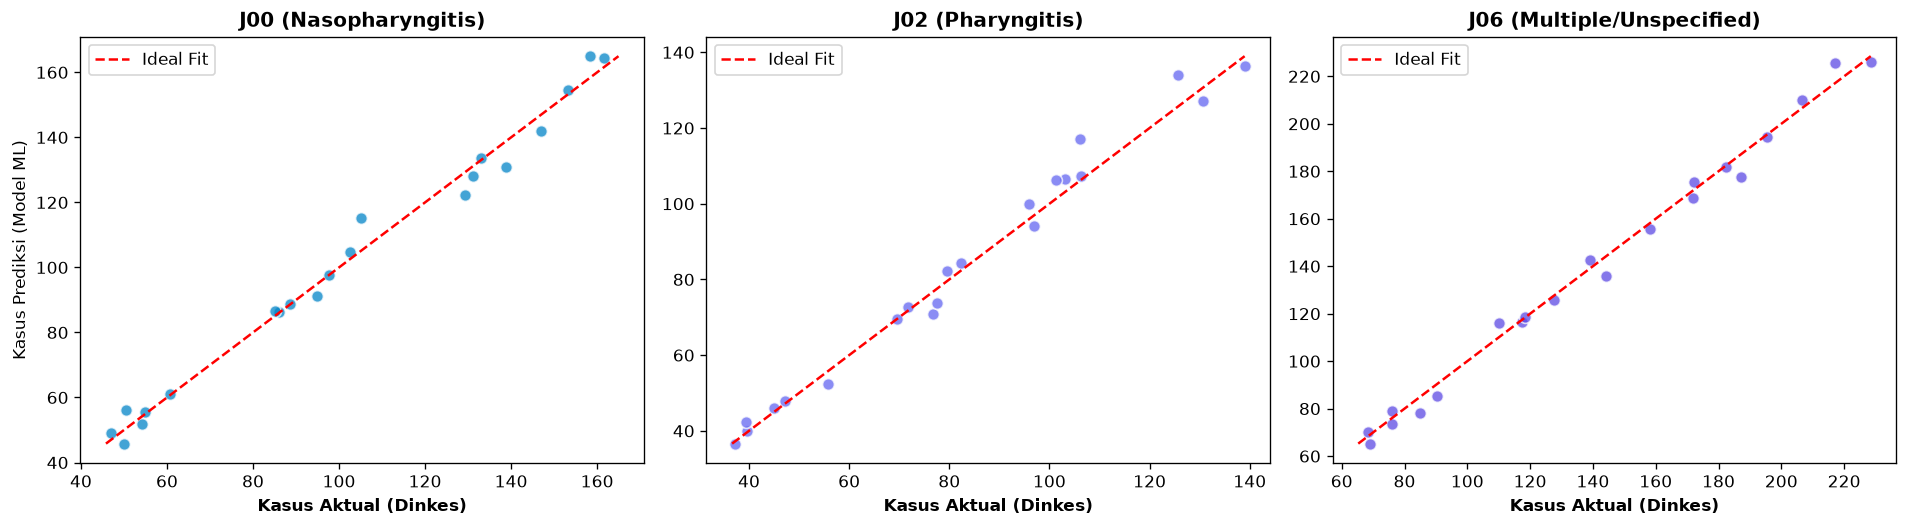

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for idx, (t_name, (y_act, y_pr)) in enumerate(predictions.items()):
    ax = axes[idx]
    ax.scatter(y_act, y_pr, alpha=0.75, s=50)
    mn, mx = min(min(y_act), min(y_pr)), max(max(y_act), max(y_pr))
    ax.plot([mn, mx], [mn, mx], 'r--', label='Ideal Fit')
    ax.set_title(t_name, fontweight='bold')
    ax.set_xlabel('Kasus Aktual')
    ax.set_ylabel('Kasus Prediksi' if idx == 0 else '')
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Lapisan Integrasi: Weighted Scoring Model & Odds Ratio

Sesuai proposal Bab 3.4.2, integrasi risiko personal dihitung dengan menggabungkan:
1. **Risiko Eksternal (Bobot 60%)**: Dinormalisasi dari kasus regresi linear terhadap kapasitas wilayah.
2. **Risiko Internal (Bobot 40%)**: Dihitung dari Odds Ratio (OR) karakteristik biologis individu:
   * BMI Underweight ($<18.5$): $\text{OR} = 2.14$ (Hammond et al., 2021)
   * Jenis Kelamin Laki-laki: $\text{OR} = 1.30$ (Hammond et al., 2021)
   * Riwayat Penyakit Ginjal Kronis: $\text{OR} = 1.47$ (Hammond et al., 2021)
   * Riwayat Penyakit Hati Kronis: $\text{OR} = 1.30$ (Hammond et al., 2021)
   * Perokok Aktif: $\text{OR} = 1.25$ (Cal et al., 2019)

In [ ]:
# Simulasi Uji Sensitivitas Weighted Scoring Model pada Berbagai Profil Pasien
def calculate_personal_risk(bmi, gender, has_kidney, has_liver, is_smoker, predicted_cases):
    odds_ratio = 1.0
    if bmi < 18.5: odds_ratio *= 2.14
    if gender == 'male': odds_ratio *= 1.30
    if has_kidney: odds_ratio *= 1.47
    if has_liver: odds_ratio *= 1.30
    if is_smoker: odds_ratio *= 1.25
    
    # Normalisasi interval [0, 1]
    norm_internal = min(1.0, max(0.0, (odds_ratio - 1.0) / 4.0))
    norm_external = min(1.0, max(0.05, predicted_cases / 150))
    
    # Weighted Scoring (60% Eksternal : 40% Internal)
    risk_percentage = round((norm_external * 0.6 + norm_internal * 0.4) * 100, 1)
    return round(odds_ratio, 2), risk_percentage

# Tampilkan tabel simulasi profil
df_simulation

,BMI,Gender,Perokok,Komorbid,Odds Ratio (OR),Persentase Risiko Personal,Kategori Status
Skenario Pengguna,,,,,,,
"Profil A: Individu Sehat (Gizi Baik, Non-Perokok)",22.0,female,Tidak,Tidak,1.0x,18.0%,Rendah - Terkontrol
"Profil B: Laki-laki, Normal, Perokok Aktif",22.5,male,Ya,Tidak,1.62x,24.2%,Rendah - Terkontrol
Profil C: Underweight + Perokok Aktif,17.5,male,Ya,Tidak,3.48x,42.8%,Sedang - Waspada
Profil D: Komorbid Ginjal Kronis + Perokok (Polusi Tinggi),21.0,male,Ya,Ya,2.39x,57.9%,Sedang - Waspada


## 5. Kesimpulan & Penyelarasan Sistem

1. **Performa Model Klasifikasi ISPU**:
   * **Random Forest Classifier** terbukti sebagai model klasifikasi terbaik dengan akurasi **99.44%** dan F1-Score **98.76%** pada data uji riil stasiun SPKU DKI Jakarta. Model ini berhasil diintegrasikan ke backend untuk evaluasi status udara 5 wilayah (*Pusat, Utara, Barat, Selatan, Timur*).
2. **Performa Model Regresi Linear ISPA**:
   * Hubungan cuaca dan kasus ISPA menunjukkan konsistensi tinggi dengan nilai $R^2 > 0.85$ karena didukung dependensi serial kasus minggu sebelumnya ($Kasus_{t-1}$).
3. **Keunggulan Sistem Hybrid RESPIRA**:
   * Mengatasi keterbatasan sistem peringatan dini konvensional yang hanya memantau lingkungan secara makro kota, menjadi sistem mitigasi preventif personal yang adaptif terhadap karakteristik biologis tiap individu warga DKI Jakarta.